In [24]:
!pip install ucimlrepo -q

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

In [26]:
cdc_diabetes = fetch_ucirepo(id=891)

In [27]:
X = cdc_diabetes.data.features
y = cdc_diabetes.data.targets

# **EDA**

In [28]:
X.shape
y.shape

(253680, 1)

In [29]:
X.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40,1,0,0,0,0,1,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,25,1,0,0,1,0,0,...,0,1,3,0,0,0,0,7,6,1
2,1,1,1,28,0,0,0,0,1,0,...,1,1,5,30,30,1,0,9,4,8
3,1,0,1,27,0,0,0,1,1,1,...,1,0,2,0,0,0,0,11,3,6
4,1,1,1,24,0,0,0,1,1,1,...,1,0,2,3,0,0,0,11,5,4


In [30]:
X.isnull().sum()

,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0
Veggies,0


In [31]:
print("سليم = 0 ، مصاب = 1")
class_dist = y.value_counts(normalize=True) * 100
print(class_dist)

سليم = 0 ، مصاب = 1
Diabetes_binary
0                  86.066698
1                  13.933302
Name: proportion, dtype: float64


/tmp/ipykernel_2539/330528625.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y.iloc[:, 0], palette="coolwarm")


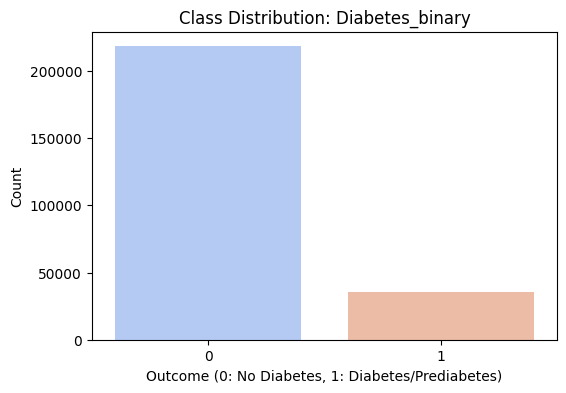

In [32]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y.iloc[:, 0], palette="coolwarm")
plt.title("Class Distribution: Diabetes_binary")
plt.xlabel("Outcome (0: No Diabetes, 1: Diabetes/Prediabetes)")
plt.ylabel("Count")
plt.show()

In [49]:
train_df = pd.concat([X_train, pd.Series(y_train, name="Diabetes_binary", index=X_train.index)], axis=1)

corr_matrix = train_df.corr()
target_corr = corr_matrix['Diabetes_binary'].sort_values(ascending=False)

print("Top features related with Diabetes:")
print(target_corr.head(7))

Top features related with Diabetes:
Diabetes_binary         1.000000
GenHlth                 0.293909
HighBP                  0.263413
DiffWalk                0.219822
BMI                     0.219193
HighChol                0.200723
HeartDiseaseorAttack    0.178000
Name: Diabetes_binary, dtype: float64


/tmp/ipykernel_2539/321837783.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='Diabetes_binary', data=train_df, palette="Set2")
/tmp/ipykernel_2539/321837783.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='Diabetes_binary', data=train_df, palette="Set2")
/tmp/ipykernel_2539/321837783.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Diabetes_binary', y=col, data=train_df, palette="Set2")
/tmp/ipykernel_2539/321837783.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be rem

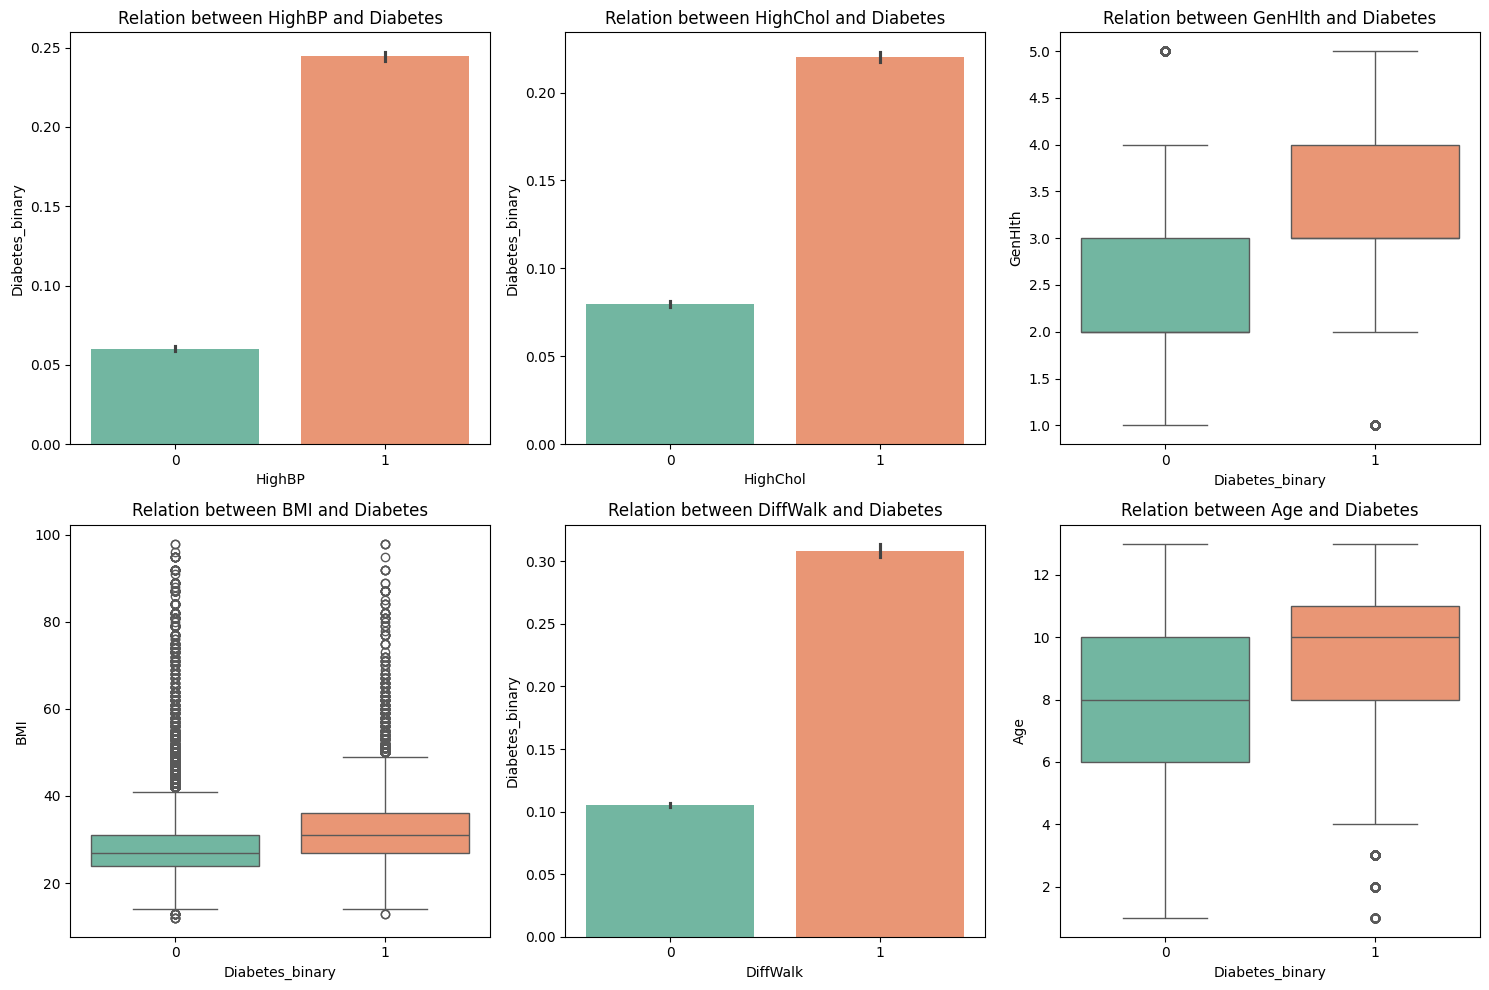

In [51]:
features_to_plot = ['HighBP', 'HighChol', 'GenHlth', 'BMI', 'DiffWalk', 'Age']

plt.figure(figsize=(15, 10))
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 3, i)
    if col in ['BMI', 'GenHlth', 'Age']:
        sns.boxplot(x='Diabetes_binary', y=col, data=train_df, palette="Set2")
    else:
        sns.barplot(x=col, y='Diabetes_binary', data=train_df, palette="Set2")
    plt.title(f"Relation between {col} and Diabetes")
plt.tight_layout()
plt.show()

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y.values.ravel(), test_size=0.2, random_state=42,stratify=y)

# **Baseline Model**

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

In [40]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_acc = baseline.score(X_test, y_test)
print(f"Baseline Accuracy: {baseline_acc:.4f}\n")

Baseline Accuracy: 0.8607



# **Logistic Regression Pipeline**

In [41]:
pipe_lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))])

pipe_lr.fit(X_train, y_train)
y_pred = pipe_lr.predict(X_test)
y_proba = pipe_lr.predict_proba(X_test)[:, 1]

In [44]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["No Diabetes (0)", "Diabetes (1)"]))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.95      0.73      0.82     43667
   Diabetes (1)       0.31      0.76      0.44      7069

       accuracy                           0.73     50736
      macro avg       0.63      0.74      0.63     50736
   weighted avg       0.86      0.73      0.77     50736

ROC-AUC Score: 0.8196


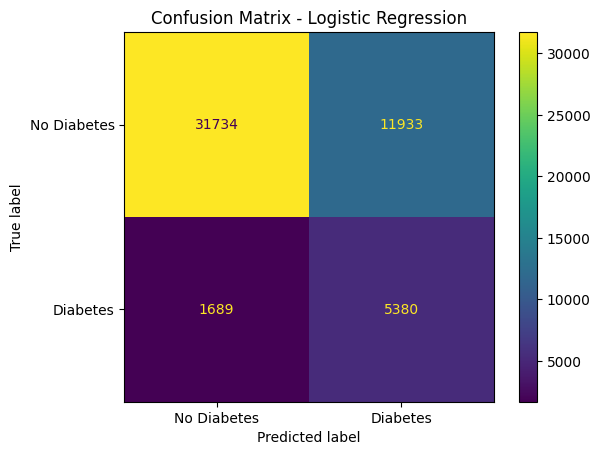

In [45]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No Diabetes", "Diabetes"])
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# **Random Forest, LightGBM, Gradient Boosting**

In [52]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

In [53]:
models = {
    "Logistic Regression": Pipeline([('scaler', StandardScaler()),('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))]),
    "Random Forest": RandomForestClassifier(n_estimators=100,max_depth=10,class_weight='balanced',random_state=42,n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_depth=8,class_weight='balanced',random_state=42)
}

# **Cross Validation**

In [55]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train,cv=cv,scoring=['roc_auc', 'recall', 'precision', 'f1'], n_jobs=-1)
    results.append({
        "Model": name,
        "ROC-AUC": scores['test_roc_auc'].mean(),
        "Recall": scores['test_recall'].mean(),
        "Precision": scores['test_precision'].mean(),
        "F1-Score": scores['test_f1'].mean()
})

comparison_df = pd.DataFrame(results)
print("Cross-Validation:")
display(comparison_df)

Cross-Validation:


,Model,ROC-AUC,Recall,Precision,F1-Score
0,Logistic Regression,0.823295,0.765605,0.311797,0.443124
1,Random Forest,0.826833,0.767691,0.314651,0.446351
2,Hist Gradient Boosting,0.830473,0.794143,0.307037,0.442850


# **Best_model**

In [57]:
best_model = HistGradientBoostingClassifier(max_depth=8,class_weight='balanced',random_state=42)
best_model.fit(X_train, y_train)

test_proba = best_model.predict_proba(X_test)[:, 1]

thresholds = [0.5, 0.45, 0.40, 0.35, 0.30]
print(f"{'Threshold':<10} | {'Recall':<10} | {'Precision':<10} | {'F1-Score':<10}")
print("-" * 45)
for th in thresholds:
    preds = (test_proba >= th).astype(int)
    report = classification_report(y_test, preds, output_dict=True)
    rec = report['1']['recall']
    prec = report['1']['precision']
    f1 = report['1']['f1-score']
    print(f"{th:<10.2f} | {rec:<10.4f} | {prec:<10.4f} | {f1:<10.4f}")

chosen_threshold = 0.40
final_preds = (test_proba >= chosen_threshold).astype(int)

Threshold  | Recall     | Precision  | F1-Score  
---------------------------------------------
0.50       | 0.7946     | 0.3055     | 0.4413    
0.45       | 0.8339     | 0.2867     | 0.4267    
0.40       | 0.8700     | 0.2706     | 0.4128    
0.35       | 0.8980     | 0.2559     | 0.3982    
0.30       | 0.9171     | 0.2401     | 0.3805    


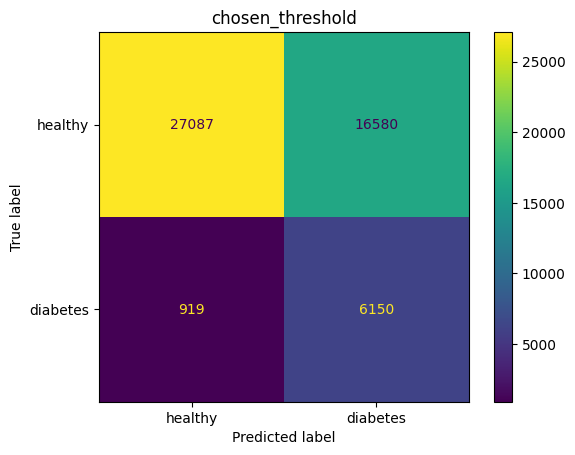

In [59]:
ConfusionMatrixDisplay.from_predictions(y_test, final_preds, display_labels=["healthy", "diabetes"])
plt.title(f"chosen_threshold")
plt.show()

# **joblib**

In [60]:
import joblib
from sklearn.inspection import permutation_importance

In [61]:
perm_importance = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
sorted_idx = perm_importance.importances_mean.argsort()[::-1]

top_7_features = X.columns[sorted_idx[:7]].tolist()
print("Top 7 Features:")
for idx, feat in enumerate(top_7_features, 1):
    print(f"{idx}. {feat}")

Top 7 Features:
1. GenHlth
2. BMI
3. Age
4. DiffWalk
5. HeartDiseaseorAttack
6. PhysHlth
7. Income


In [62]:
X_train_top7 = X_train[top_7_features]
X_test_top7 = X_test[top_7_features]

In [63]:
final_screening_pipeline = Pipeline([('clf', HistGradientBoostingClassifier(max_depth=6, class_weight='balanced', random_state=42))])

final_screening_pipeline.fit(X_train_top7, y_train)

Pipeline(steps=[('clf',
                 HistGradientBoostingClassifier(class_weight='balanced',
                                                max_depth=6,
                                                random_state=42))])

In [67]:
top7_proba = final_screening_pipeline.predict_proba(X_test_top7)[:, 1]
top7_preds = (top7_proba >= chosen_threshold).astype(int)

print("\n 7_Features_Report")
print(classification_report(y_test, top7_preds, target_names=["Healthy", "diabetes"]))


 7_Features_Report
              precision    recall  f1-score   support

     Healthy       0.96      0.59      0.73     43667
    diabetes       0.25      0.86      0.39      7069

    accuracy                           0.63     50736
   macro avg       0.61      0.72      0.56     50736
weighted avg       0.86      0.63      0.69     50736



In [68]:
model_payload = {
    "model": final_screening_pipeline,
    "features": top_7_features,
    "threshold": chosen_threshold
}
joblib.dump(model_payload, "diabetes_screening_model.joblib")
print("\n Imported Successfully diabetes_screening_model.joblib")


 Imported Successfully diabetes_screening_model.joblib
